# Oil products demand — 01 Data pipeline: US jet fuel

**Purpose.** Take two public sources from their raw files to one point-in-time modelling dataset: US jet fuel demand as EIA measures it, and a physical indicator readable the next day, the kerosene burned by the commercial jets that leave US airports, computed flight by flight from the ADS-B record of the OpenSky Network. Show for every variable where it comes from, how it was processed and from when it could legitimately be used. `02_model_jet.ipynb` only reads the tables this pipeline writes.

**Run order.** `python -m src.download` (optional; `opensky` needs a Trino account) → this notebook → `01_data_naphtha.ipynb` → `python -m src.model` (the backtests, about an hour) → `02_model_jet.ipynb`. The two build cells below are the same as `python -m src.sql` and `python -m src.data`.

| Step | Where | Output |
|---|---|---|
| Ingestion | `src/download.py`, `src/flights.py` | `data/US_jet_fuel/eia_*.csv`, `aircraft.csv`, `fuel_table.csv`, `opensky/*.csv` |
| Raw layer | `src/sql.py` | DuckDB table `raw`: every observation, every vintage seen |
| Clean layer | `src/sql.py` | DuckDB tables `demand`, `predictors`, `catalog` |
| Alignment | `src/data.py` | DuckDB table `panel`, read by `src/model.py` and notebook 02 |

**State of the burn index.** OpenSky granted access to its Trino database on 20 November 2026, in a week when its flights before 2023 were offline. The index therefore starts in January 2023; the download resumes from where it stopped once the older days return (section 9).

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as c, data, flights, sql

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.figsize": (10, 3), "axes.grid": True, "grid.alpha": .3})

## 1. Ingestion: raw files into DuckDB

`sql.build()` appends to `raw` whatever the files hold that the table does not: new observations and revised values, each stamped with `ingested_at`, the time its file was downloaded. Nothing is ever updated or deleted, so the load is idempotent and a revision is kept next to the value it replaces. It loads the files of every product.

In [2]:
sql.build()

      0 rows added to raw from US_jet_fuel/eia_monthly.csv
      0 rows added to raw from US_jet_fuel/eia_weekly.csv
      0 rows added to raw from US_jet_fuel/opensky/2022-12.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-01.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-02.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-03.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-04.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-05.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-06.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-07.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-08.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-09.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-10.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-11.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-12.csv
      0 rows added to raw from US_jet_fuel/opensky/2024-01.csv
 

In [3]:
sql.build()  # a second run adds nothing

      0 rows added to raw from US_jet_fuel/eia_monthly.csv
      0 rows added to raw from US_jet_fuel/eia_weekly.csv
      0 rows added to raw from US_jet_fuel/opensky/2022-12.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-01.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-02.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-03.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-04.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-05.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-06.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-07.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-08.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-09.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-10.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-11.csv
      0 rows added to raw from US_jet_fuel/opensky/2023-12.csv
      0 rows added to raw from US_jet_fuel/opensky/2024-01.csv
 

In [4]:
sql.query("DESCRIBE raw")[["column_name", "column_type"]]

,column_name,column_type
0,file,VARCHAR
1,series,VARCHAR
2,obs_date,DATE
3,value,DOUBLE
4,ingested_at,TIMESTAMP


In [5]:
# what entered from the jet files, and when
sql.query("""
    SELECT file, CAST(MAX(ingested_at) AS DATE) AS ingested, COUNT(DISTINCT series) AS series, COUNT(*) AS observations,
           MIN(obs_date) AS first_date, MAX(obs_date) AS last_date
    FROM raw WHERE file LIKE 'US_jet_fuel/%' GROUP BY 1 ORDER BY 1
""")

,file,ingested,series,observations,first_date,last_date
0,US_jet_fuel/eia_monthly.csv,2026-11-19,1,740,1965-01-15,2026-08-15
1,US_jet_fuel/eia_weekly.csv,2026-11-19,1,1867,1991-02-08,2026-11-13
2,US_jet_fuel/opensky/2022-12.csv,2026-11-20,204,2336,2022-12-20,2022-12-31
3,US_jet_fuel/opensky/2023-01.csv,2026-11-20,220,4652,2023-01-01,2023-01-31
4,US_jet_fuel/opensky/2023-02.csv,2026-11-20,216,5764,2023-02-01,2023-02-28
5,US_jet_fuel/opensky/2023-03.csv,2026-11-20,216,6452,2023-03-01,2023-03-31
6,US_jet_fuel/opensky/2023-04.csv,2026-11-20,220,6240,2023-04-01,2023-04-30
7,US_jet_fuel/opensky/2023-05.csv,2026-11-20,224,6460,2023-05-01,2023-05-31
8,US_jet_fuel/opensky/2023-06.csv,2026-11-20,224,6012,2023-06-01,2023-06-30
9,US_jet_fuel/opensky/2023-07.csv,2026-11-20,224,6372,2023-07-01,2023-07-31


## 2. Sources and conventions

`catalog` is the data dictionary, stored next to the data. The publication lag is the one number the model depends on; it lives in `config.py` and is added here.

In [6]:
catalog = sql.query("SELECT * FROM catalog WHERE product = 'jet'")
catalog[["variable", "source", "source_id", "definition", "unit", "frequency", "date_stamp", "release"]]

,variable,source,source_id,definition,unit,frequency,date_stamp,release
0,demand,EIA Petroleum Supply Monthly,MKJUPUS2,Kerosene-type jet fuel product supplied,kb/d,monthly,15th of the month,end of the second month after
1,product_supplied_weekly,EIA Weekly Petroleum Status Report,WKJUPUS2,Kerosene-type jet fuel product supplied (weekly estimate; context only),kb/d,weekly,Friday ending the week,Wednesday after the week
2,burn,OpenSky Network flights_data4 with OpenAP,flights_data4 + aircraft database,Fuel burned by commercial jets leaving US airports (28-day mean),kb/d,daily,UTC day the flight ended,the next day
3,flights,OpenSky Network flights_data4,flights_data4,Departures of commercial jets from US airports (coverage; context only),flights,daily,UTC day the flight ended,the next day
4,unknown_airport,OpenSky Network flights_data4,flights_data4,Share of the flights the index could count that lack an estimated airport (coverage; context only),share,daily,UTC day the flight ended,the next day


In [7]:
pd.DataFrame({"lag": {"demand": f"{c.DEMAND_LAG['jet']} months", "product_supplied_weekly": f"{c.WEEKLY_LAG_DAYS} days (context)",
                      "burn": f"{c.BURN_LAG_DAYS} day"}})

,lag
demand,2 months
product_supplied_weekly,6 days (context)
burn,1 day


- **EIA.** The target is kerosene-type jet fuel product supplied from the Petroleum Supply Monthly (`MKJUPUS2`), in kb/d, published at the end of the second month after. The weekly figure of the Weekly Petroleum Status Report (`WKJUPUS2`) is the same concept a week after the fact: it is kept as the yardstick the burn index has to beat, not as a feature.
- **OpenSky Network.** Every flight its receivers closed on a UTC day, with estimated departure and arrival airports (`flights_data4`, kept from 2016, of which only the days from 20 December 2022 were online in November 2026), joined to OpenSky's aircraft database for the type. Section 9 turns them into the index.

Four dates are kept apart throughout:

- **Observation date** — `period_end`, the last day of the period the number describes: a month, a week, a day.
- **Availability date** — `available_at`, when the number was published: `period_end` plus the source's lag. This is the date every join uses.
- **Ingestion date** — `ingested_at`, when the file entered this database.
- **Vintage** — which version of a revised number. EIA publishes only its latest version, so the database holds vintages only from its first download on (section 5).

## 3. Clean layer

`demand` and `predictors` are rebuilt from the latest value of every raw observation. Cleaning is limited to standardisation: one date convention (`period_end`), one name per variable. No value is filled, smoothed or removed.

In [8]:
sql.query("SELECT product, unit, MIN(period_end) AS first, MAX(period_end) AS last, COUNT(*) AS months FROM demand WHERE product = 'jet' GROUP BY 1, 2")

,product,unit,first,last,months
0,jet,kb/d,1965-01-31,2026-08-31,740


In [9]:
sql.query("SELECT variable, MIN(period_end) AS first, MAX(period_end) AS last, COUNT(*) AS observations FROM predictors WHERE product = 'jet' GROUP BY 1 ORDER BY 1")

,variable,first,last,observations
0,burn,2022-12-20,2026-11-18,1409
1,flights,2022-12-20,2026-11-18,1409
2,product_supplied_weekly,1991-02-08,2026-11-13,1867
3,unknown_airport,2022-12-20,2026-11-18,1409


## 4. Validation of the clean tables

In [10]:
# keys, missing values, impossible values, over the sample the model uses (2000 on)
sql.query(f"""
    SELECT 'demand' AS table_name, COUNT(*) AS rows, COUNT(*) - COUNT(DISTINCT (product, period_end)) AS duplicates,
           COUNT(*) FILTER (WHERE value IS NULL) AS missing, COUNT(*) FILTER (WHERE value <= 0) AS not_positive
    FROM demand WHERE product = 'jet' AND period_end >= DATE '{c.SAMPLE_START}'
    UNION ALL
    SELECT 'predictors', COUNT(*), COUNT(*) - COUNT(DISTINCT (product, variable, period_end)),
           COUNT(*) FILTER (WHERE value IS NULL), COUNT(*) FILTER (WHERE value <= 0)
    FROM predictors WHERE product = 'jet' AND period_end >= DATE '{c.SAMPLE_START}'
""")

,table_name,rows,duplicates,missing,not_positive
0,demand,320,0,0,0
1,predictors,5629,0,0,0


In [11]:
# frequency: days between consecutive observations of each series, since 2000
gaps = sql.query("""
    SELECT variable, period_end, period_end - LAG(period_end) OVER (PARTITION BY variable ORDER BY period_end) AS gap_days
    FROM (SELECT variable, period_end FROM predictors WHERE product = 'jet' UNION ALL SELECT 'demand', period_end FROM demand WHERE product = 'jet')
    WHERE period_end >= DATE '2000-01-01'
""")
gaps.groupby("variable")["gap_days"].agg(["median", "max"])

,median,max
variable,,
burn,1.00,7
demand,31.00,31
flights,1.00,7
product_supplied_weekly,7.00,7
unknown_airport,1.00,7


In [12]:
# suspicious values: the largest month-on-month moves of the target, in %
moves = sql.query("""
    SELECT period_end, value, 100 * (value / LAG(value) OVER (ORDER BY period_end) - 1) AS move_pct
    FROM demand WHERE product = 'jet' AND period_end >= DATE '2000-01-01'
""")
moves.loc[moves["move_pct"].abs().nlargest(6).index].sort_values("period_end")

,period_end,value,move_pct
36,2003-01-31,"1,505.00",-12.60
61,2005-02-28,"1,743.00",13.48
242,2020-03-31,"1,388.00",-14.27
243,2020-04-30,678.00,-51.15
245,2020-06-30,784.00,31.32
246,2020-07-31,968.00,23.47


In [13]:
# cross-check between two EIA products: the weekly estimate averaged over each month against the monthly
# figure published two months later, absolute gap in %
check = sql.query("""
    SELECT d.period_end, d.value AS monthly, w.weekly
    FROM demand d
    JOIN (SELECT last_day(period_end) AS period_end, AVG(value) AS weekly
          FROM predictors WHERE product = 'jet' AND variable = 'product_supplied_weekly' GROUP BY 1) w USING (period_end)
    WHERE d.product = 'jet' AND d.period_end >= DATE '2000-01-01'
""")
check["gap_pct"] = 100 * (check["weekly"] / check["monthly"] - 1).abs()
check["gap_pct"].describe()[["count", "mean", "50%", "max"]].to_frame("weekly vs monthly, % gap").T

,count,mean,50%,max
"weekly vs monthly, % gap",320.00,2.87,2.49,12.43


- **No duplicate, no missing value, nothing negative or zero** in either table since 2000.
- **Frequencies as expected**: a month between two demand prints, a week between two weekly ones, a day between two days of the burn index. Its longest gap, seven days, is the documented OpenSky outage of 18 to 23 January 2023.
- **Large moves are real**: the largest monthly moves of demand are the 2020 lockdown (−51% in April, +31% in June) and two early-2000s months (−13% in January 2003, +13% in February 2005). None is removed.
- **The two EIA products agree**: averaged over each month, the weekly estimate is within 2.9% of the monthly figure published two months later (median 2.5%, 12.4% at worst). That is the bar a faster indicator has to clear.

## 5. Point-in-time: publication lags and revisions

**Lags.** A number cannot be used before it is published. Each series gets `available_at = period_end + lag`, with the lag read off the source's release calendar (section 2): two month ends for the monthly target, the day after for the burn index.

**Are the lags right?** They can be tested against a real download. At the time of the latest ingestion, the convention says which period of each series should already be published; the file says which period actually was. The convention must never be ahead of the file.

In [14]:
ingested = sql.query("SELECT MAX(ingested_at) AS t FROM raw WHERE file LIKE 'US_jet_fuel/eia%'")["t"].iloc[0]
origin = ingested.normalize() - pd.offsets.MonthEnd(1)  # the last month end before the download
newest = sql.query("SELECT MAX(period_end) AS newest FROM demand WHERE product = 'jet'")["newest"].iloc[0]
allowed = origin - pd.offsets.MonthEnd(c.DEMAND_LAG["jet"])
weekly = sql.query("SELECT MAX(period_end) AS newest FROM predictors WHERE product = 'jet' AND variable = 'product_supplied_weekly'")["newest"].iloc[0]
assert newest >= allowed and weekly + pd.Timedelta(days=c.WEEKLY_LAG_DAYS) <= ingested
print(f"downloaded {ingested:%d %b %Y}, forecast origin {origin:%d %b %Y}: the convention allows demand to {allowed:%B %Y}, "
      f"the file holds {newest:%B %Y}; the newest week ends {weekly:%d %b %Y}")
# the burn index: a day is on file only once it has ended, and was read no earlier than the next day
burn_day = sql.query("SELECT MAX(period_end) AS d FROM predictors WHERE product = 'jet' AND variable = 'burn'")["d"].iloc[0]
burn_read = sql.query("SELECT MAX(ingested_at) AS t FROM raw WHERE file LIKE 'US_jet_fuel/opensky/%'")["t"].iloc[0]
assert pd.Timestamp(burn_day) + pd.Timedelta(days=c.BURN_LAG_DAYS) <= burn_read
print(f"burn index: newest day {burn_day:%d %b %Y}, read on {burn_read:%d %b %Y}")

downloaded 19 Nov 2026, forecast origin 31 Oct 2026: the convention allows demand to August 2026, the file holds August 2026; the newest week ends 13 Nov 2026
burn index: newest day 18 Nov 2026, read on 20 Nov 2026


The convention is never ahead of the file. At the 31 October origin the two-month lag allows August 2026, and the file downloaded on 19 November holds August as its newest month: September, due at the end of November, was not out yet. The weekly figure for the week to 13 November was on file six days later. The burn index of 18 November was read on 20 November: a day is never on file before it has ended.

**Revisions.** A lag stops a number from being used before it existed. It does not undo the fact that today's file shows the number as later revised. EIA publishes only its latest figures, so the dataset is built from current values: **publication delays are handled, revisions are not**.

In [15]:
sql.query("""
    SELECT file, COUNT(DISTINCT ingested_at) AS downloads, COUNT(*) FILTER (WHERE vintages > 1) AS revised_observations
    FROM latest WHERE file LIKE 'US_jet_fuel/%' GROUP BY 1 ORDER BY 1
""")

,file,downloads,revised_observations
0,US_jet_fuel/eia_monthly.csv,1,0
1,US_jet_fuel/eia_weekly.csv,1,0
2,US_jet_fuel/opensky/2022-12.csv,1,0
3,US_jet_fuel/opensky/2023-01.csv,1,0
4,US_jet_fuel/opensky/2023-02.csv,1,0
5,US_jet_fuel/opensky/2023-03.csv,1,0
6,US_jet_fuel/opensky/2023-04.csv,1,0
7,US_jet_fuel/opensky/2023-05.csv,1,0
8,US_jet_fuel/opensky/2023-06.csv,1,0
9,US_jet_fuel/opensky/2023-07.csv,1,0


No revision yet: each file was read once, the OpenSky files of August 2024 and October 2026 three times while they were being written, with no value changed. Two facts limit what this can show. EIA keeps only its latest figures. And OpenSky recomputes its flight table when it changes its processing, as it did on 13 and 14 August 2026: the database holds the version read on 20 November 2026, not the one a forecaster would have seen at the time.

## 6. Alignment

Every driver is joined to a complete monthly index. A row for month *t* is a forecast origin: what was published by the last day of *t*. The join is `merge_asof(direction="backward")` on `available_at`, with a tolerance of `STALE_DAYS` days past which a value is left missing rather than carried. The burn index is daily: at the end of month *t* the newest day readable is the one before, so a row carries the mean of the 28 days to the day before its month end, the way EIA itself reports its weekly figures as four-week averages.

In [16]:
panel = data.align("jet")
print(f"{len(panel)} rows in the jet panel, drivers: {sorted(panel['variable'].unique()) if len(panel) else 'none yet'}")

322 rows in the jet panel, drivers: ['burn']


In [17]:
# by hand for the month end of June 2025: the newest day readable is 29 June, so the row carries the mean of 2 to 29 June
burn = sql.query("SELECT period_end, value FROM predictors WHERE product = 'jet' AND variable = 'burn'").set_index("period_end")["value"]
burn.index = pd.to_datetime(burn.index)
burn = burn.sort_index()
by_hand = burn.loc["2025-06-02":"2025-06-29"].mean()
row = panel[(panel["variable"] == "burn") & (panel["month"] == "2025-06-01")]
assert abs(row["value"].iloc[0] - by_hand) < 1e-9 and row["period_end"].iloc[0] == pd.Timestamp("2025-06-29")
row

,product,variable,month,month_end,period_end,value,available_at
305,jet,burn,2025-06-01,2025-06-30,2025-06-29,"1,241.24",2025-06-30


By hand for June 2025: the newest day readable at the end of June is the 29th, so the row carries the mean of 2 to 29 June, 1,241 kb/d, published on the 30th. `data.align` gives the same number.

## 7. Validation after alignment

A backward join guarantees that `available_at` is not later than the origin. It is only as good as `available_at` itself, which is why the lags were tested in section 5. The assertions below are the conditions the model relies on; they run on whatever the panel holds.

In [18]:
matched = panel.dropna(subset="value")
age = (matched["month_end"] - matched["period_end"]).dt.days
# no look-ahead: every value on a row was published by the row's month end, and describes a period that had ended
assert (matched["available_at"] <= matched["month_end"]).all()
assert (matched["period_end"] <= matched["month_end"]).all()
# no stale value: nothing older than the tolerance was carried forward
assert (age <= c.STALE_DAYS).all()
assert not panel.duplicated(["product", "variable", "month"]).any()

In [19]:
# the target obeys the same rule inside the model: at origin t the newest demand print is t minus its lag
jet = data.demand("jet")
pd.DataFrame({"demand": jet["demand"], "newest print at the origin": jet["demand"].shift(c.DEMAND_LAG["jet"])}).tail(3)

,demand,newest print at the origin
month,,
2026-06-01,"1,817.00","1,814.00"
2026-07-01,"1,890.00","1,706.00"
2026-08-01,"1,797.00","1,817.00"


## 8. Final dataset

`data.build()` stores the aligned panel of every product. `data.dataset("jet")` reads it back as the modelling frame: demand, then every driver as readable at that month end.

In [20]:
data.build()

,product,drivers,first,last,rows
0,jet,1,2000-01-01,2026-10-01,322
1,naphtha_jp,1,2000-01-01,2026-11-01,323
2,naphtha_kr,1,2000-01-01,2026-11-01,323


In [21]:
df = data.dataset("jet")
pd.Series({"rows": len(df), "drivers": df.shape[1] - 1, "first": df.index.min(), "last origin": df.index.max(),
           "last demand": df["demand"].last_valid_index()}).to_frame("jet").T

,rows,drivers,first,last origin,last demand
jet,322,1,2000-01-01 00:00:00,2026-10-01 00:00:00,2026-08-01 00:00:00


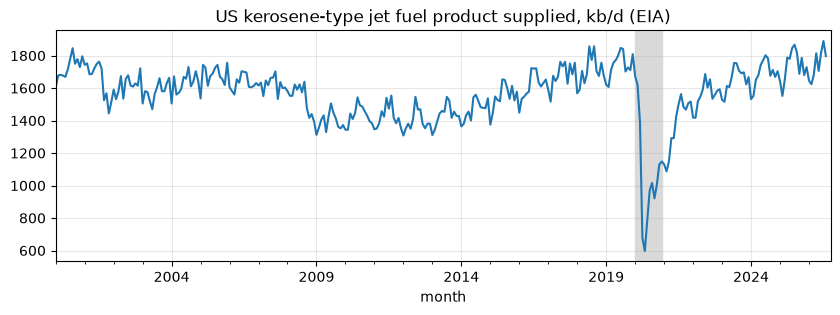

In [22]:
ax = df["demand"].plot(title="US kerosene-type jet fuel product supplied, kb/d (EIA)")
ax.axvspan(pd.Timestamp(c.COVID[0]), pd.Timestamp(c.COVID[1]), color="0.85"); ax.set_xlabel("month");

**What this dataset is and is not.**

- Every value was published by the month end of its row, under release-calendar lags that a real download confirms are not too short.
- It is **not** a vintage dataset. Values are today's, including later revisions.
- The burn index starts in December 2022, so its year-on-year change, the form the model uses, exists only from January 2024: for most of the backtest the model runs on lagged demand alone (notebook 02).

## 9. The kerosene burn index

**The query.** One UTC day per query, filtered on the `day` partition, the flights that leave or reach an airport whose ICAO code starts with K, PA or PH. Queries run one at a time, under OpenSky's limit of two. The login stays in pyopensky's own settings file.

In [23]:
print(flights.query("2025-07-01"))

SELECT icao24, estdepartureairport, estarrivalairport FROM flights_data4 WHERE day = 1751328000 AND (estdepartureairport LIKE 'K%' OR estdepartureairport LIKE 'PA%' OR estdepartureairport LIKE 'PH%' OR estarrivalairport LIKE 'K%' OR estarrivalairport LIKE 'PA%' OR estarrivalairport LIKE 'PH%')


In [24]:
# the days that touch a window OpenSky lost for good: they will be missing, not zero
lost = sorted({d for start, end in c.OPENSKY_OUTAGES for d in pd.date_range(pd.Timestamp(start).normalize(), pd.Timestamp(end).normalize())})
pd.Series([d.strftime("%Y-%m-%d") for d in lost], name="days missing").to_frame().T

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
days missing,2023-01-02,2023-01-03,2023-01-18,2023-01-19,2023-01-20,2023-01-21,2023-01-22,2023-01-23,2023-06-21,2023-11-15,...,2023-11-20,2023-12-02,2023-12-03,2023-12-04,2023-12-05,2024-05-20,2024-05-21,2026-01-02,2026-01-03,2026-01-24


**The types.** `flights_data4` gives no aircraft type. The type is joined on the transponder address `icao24` from OpenSky's aircraft database, one snapshot (August 2025) used for every year. Only the commercial jets of `config.COMMERCIAL_JETS` are kept, each mapped to an OpenAP model.

In [25]:
aircraft = pd.read_csv(c.JET / "aircraft.csv", dtype=str)
fleet = aircraft["typecode"].value_counts().rename("aircraft").to_frame()
fleet["OpenAP model"] = fleet.index.map(c.COMMERCIAL_JETS)
fleet["proxy"] = fleet.index.str.lower() != fleet["OpenAP model"]
print(f"{len(aircraft):,} commercial jets in the database, {fleet['proxy'].mul(fleet['aircraft']).sum() / fleet['aircraft'].sum():.0%} of them burned through a proxy")
fleet.head(12)

43,760 commercial jets in the database, 6% of them burned through a proxy


,aircraft,OpenAP model,proxy
typecode,,,
B738,6781,b738,False
A320,6184,a320,False
A20N,2501,a20n,False
A321,2234,a321,False
A21N,2003,a21n,False
B38M,1852,b38m,False
A319,1842,a319,False
B737,1410,b737,False
B763,1063,b763,False


**The fuel table.** For each OpenAP model, a complete flight (climb, cruise, descent) for each cruise range, integrated every 30 seconds with the mass falling from 85% of MTOW as fuel is burned. A flight shorter than the shortest complete one, about 650 km, is read on a line from zero.

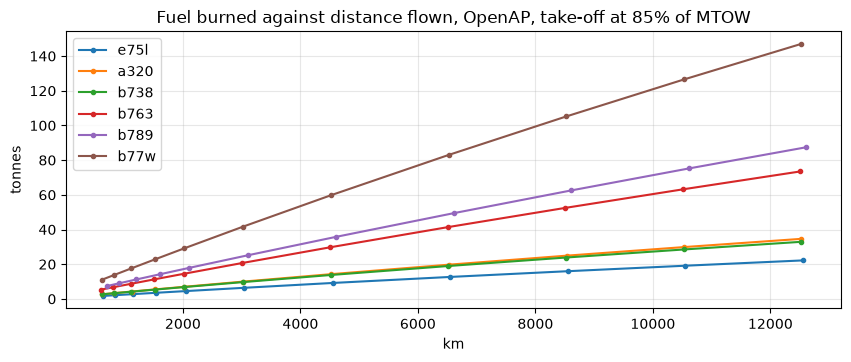

In [26]:
table = pd.read_csv(flights.FUEL_TABLE)
fig, ax = plt.subplots(figsize=(10, 3.6))
for model in ["e75l", "a320", "b738", "b763", "b789", "b77w"]:
    curve = table[table["model"] == model]
    ax.plot(curve["km"], curve["fuel_kg"] / 1000, marker="o", ms=3, label=model)
ax.set_title("Fuel burned against distance flown, OpenAP, take-off at 85% of MTOW"); ax.set_xlabel("km"); ax.set_ylabel("tonnes"); ax.legend();

In [27]:
# a unit check by hand: an A320 from New York JFK to Los Angeles
km = flights.distance(pd.Series(["KJFK"]), pd.Series(["KLAX"]))[0]
curve = table[table["model"] == "a320"]
fuel = np.interp(km, [0, *curve["km"]], [0, *curve["fuel_kg"]])  # as flights.burn reads the table
pd.Series({"great circle, km": km, "fuel, kg": fuel, "kg per km": fuel / km, "barrels": fuel / c.KG_PER_BARREL})

great circle, km    3,972.21
fuel, kg           12,677.88
kg per km               3.19
barrels                99.67
dtype: float64

About 12.7 tonnes, or 100 barrels, for 3,972 km: the right order of magnitude for an A320 across the United States, which burns some 2.5 tonnes an hour for five to six hours. The great circle is shorter than the route flown, one of the reasons the index sits below EIA's figure.

**The index.** `python -m src.download opensky` asked OpenSky for one UTC day at a time, newest first, and stopped at the first day for which it returned no flight. It ran on 20 November 2026, two queries at a time at most, 8 to 30 seconds a day, and stopped at 19 December 2022: OpenSky's flights before that were offline that week. The index holds **1,409 days, from 20 December 2022 to 18 November 2026**; the 21 days missing in between are exactly OpenSky's documented outages, which are not asked for. The first day, 20 December 2022, is the partial edge of what was online.

In [28]:
# what came back, by year: days on file, departures counted, the index and the share of flights OpenSky could not place
daily = sql.query("""
    SELECT period_end AS day, variable, value FROM predictors
    WHERE product = 'jet' AND variable IN ('burn', 'flights', 'unknown_airport')
""").pivot(index="day", columns="variable", values="value")
daily.index = pd.to_datetime(daily.index)
daily.groupby(daily.index.year).agg(days=("burn", "count"), departures_a_day=("flights", "mean"), burn_kbd=("burn", "mean"),
                                    no_airport_pct=("unknown_airport", lambda s: 100 * s.mean()))

,days,departures_a_day,burn_kbd,no_airport_pct
day,,,,
2022,12,"10,658.17",717.91,33.68
2023,349,"16,709.88","1,048.63",24.65
2024,364,"17,249.68","1,090.52",25.66
2025,365,"18,522.89","1,165.73",22.75
2026,319,"18,775.63","1,163.44",19.16


,count,mean,std,min,max
EIA monthly / index,42.00,1.53,0.07,1.40,1.74


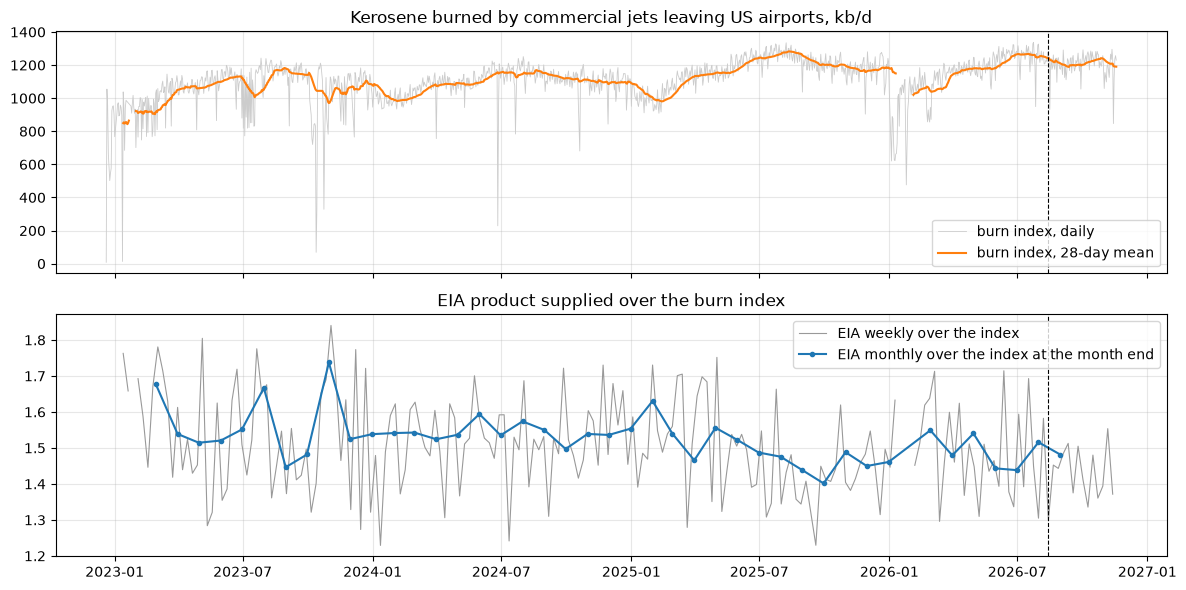

In [29]:
# the index as the model reads it, the 28-day mean, against EIA's monthly figure and its weekly estimate, kb/d
index = data.predictors("jet")["burn"]
weekly = sql.query("SELECT period_end, value FROM predictors WHERE product = 'jet' AND variable = 'product_supplied_weekly'")
weekly = weekly.set_index(pd.to_datetime(weekly["period_end"]))["value"].sort_index()
monthly = data.demand("jet")["demand"]
monthly.index = monthly.index + pd.offsets.MonthEnd(0)
start = daily.index.min()
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(daily["burn"], color="0.8", lw=.6, label="burn index, daily")
axes[0].plot(index, color="C1", label="burn index, 28-day mean")
axes[0].set_title("Kerosene burned by commercial jets leaving US airports, kb/d"); axes[0].legend()
ratio = (monthly / index.reindex(monthly.index - pd.Timedelta(days=1)).set_axis(monthly.index)).dropna()  # as the model reads it
axes[1].plot(weekly.loc[start:] / index.reindex(weekly.loc[start:].index, method="ffill"), color="0.6", lw=.8, label="EIA weekly over the index")
axes[1].plot(ratio, color="C0", marker="o", ms=3, label="EIA monthly over the index at the month end")
axes[1].set_title("EIA product supplied over the burn index"); axes[1].legend()
for ax in axes:
    ax.axvline(pd.Timestamp(c.OPENSKY_REPROCESSED), color="k", lw=.8, ls="--")
plt.tight_layout();
ratio.describe()[["count", "mean", "std", "min", "max"]].to_frame("EIA monthly / index").T

- **The level gap is stable.** Over 42 month ends from February 2023 to August 2026, EIA's figure is 1.53 times the index on average, between 1.40 and 1.74, with a standard deviation of 0.07. A gap is expected: ADS-B misses flights, a great circle is shorter than the route, and product supplied also counts military, general aviation and fuel bought for later.
- **But it drifts.** The ratio averages 1.56 in 2023 and 1.54 in 2024, then 1.49 in 2025 and 2026: the index grows 3% to 5% faster than demand, which is OpenSky's coverage growing (below).
- **The peaks are data, not demand.** July and October 2023 (1.67 and 1.74) are months with degraded days that the lost-day rule only partly catches. January 2026 is missing from the chart: with the outages of 2-3 and 24 January and the degraded 4-12 January, fewer than 21 days are left in the window that ends on the 30th. The model's row for that month carries the newest mean that has enough days, the one to 10 January, 21 days old.

In [30]:
# the days left out of the 28-day mean: OpenSky's documented outages, never downloaded, and the days whose own coverage
# says data were lost: fewer than half the departures of the four weeks before, or more than 40% of flights without an airport
lost = data.lost_days()
dropped = daily.reindex(lost[lost].index)[["flights", "unknown_airport", "burn"]]
dropped.insert(0, "documented outage", dropped["flights"].isna())
dropped.round(2)

variable,documented outage,flights,unknown_airport,burn
period_end,,,,
2022-12-20,False,177.00,0.71,8.51
2023-01-02,True,NaN,NaN,NaN
2023-01-03,True,NaN,NaN,NaN
2023-01-12,False,173.00,0.72,13.35
2023-01-18,True,NaN,NaN,NaN
2023-01-19,True,NaN,NaN,NaN
2023-01-20,True,NaN,NaN,NaN
2023-01-21,True,NaN,NaN,NaN
2023-01-22,True,NaN,NaN,NaN


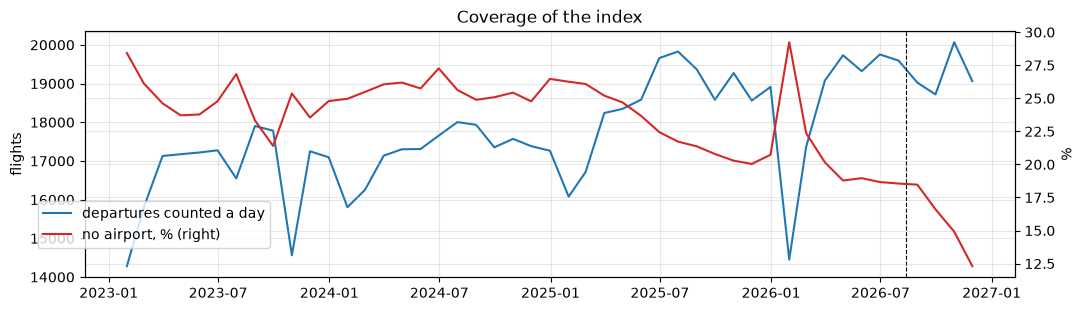

In [31]:
# coverage: departures counted a day and the share of flights OpenSky left without an airport, monthly
coverage = daily.loc["2023":].resample("ME").mean()  # December 2022 holds 12 days, the first one partial
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(coverage["flights"], color="C0", label="departures counted a day")
ax.set_ylabel("flights")
ax2 = ax.twinx(); ax2.plot(100 * coverage["unknown_airport"], color="C3", label="no airport, % (right)"); ax2.set_ylabel("%")
ax.axvline(pd.Timestamp(c.OPENSKY_REPROCESSED), color="k", lw=.8, ls="--")
ax.set_title("Coverage of the index"); fig.legend(loc="lower left", bbox_to_anchor=(.08, .18));

In [32]:
# which types burn the fuel: share of the index by aircraft type, last twelve months on file
types = sql.query(f"""
    SELECT split_part(series, ' / ', 1) AS typecode, SUM(value) AS fuel_kg FROM latest
    WHERE file LIKE 'US_jet_fuel/opensky/%' AND series LIKE '%/ fuel_kg'
      AND obs_date > (SELECT MAX(obs_date) FROM latest WHERE file LIKE 'US_jet_fuel/opensky/%') - INTERVAL 365 DAY
    GROUP BY 1 ORDER BY 2 DESC
""")
types["share, %"] = 100 * types["fuel_kg"] / types["fuel_kg"].sum()
types["OpenAP model"] = types["typecode"].map(c.COMMERCIAL_JETS)
types.head(10)[["typecode", "OpenAP model", "share, %"]]

,typecode,OpenAP model,"share, %"
0,B738,b738,8.69
1,B77W,b77w,7.54
2,A321,a321,6.65
3,B772,b772,5.69
4,B763,b763,5.16
5,B77L,b77l,5.08
6,B38M,b38m,4.65
7,B744,b744,4.49
8,B789,b789,4.38
9,B739,b739,4.32


- **Lost days.** Beyond the 21 documented outage days, the rule drops 16 more: the partial edge of 20 December 2022; 12 January, 13-14 and 24-25 October 2023, 26 June and 20 October 2024, with a fraction of the usual departures or 40% to 73% of the flights unplaced; 4 to 12 January 2026, when OpenSky could not place about half the flights for a week; and 25 January 2026, at 45% of the usual departures, which may be the winter storm rather than a loss. No public holiday is dropped: Thanksgiving and Christmas fall by a third at most, and their share of flights without an airport stays normal.
- **Coverage steps up in 2025.** The departures counted a day go from about 17,200 in 2023-2024 to 18,900-19,700 from mid-2025, while the share of flights without an airport falls from 25-26% in 2024 to 18-21%: OpenSky placed more flights, airlines did not fly 10% more (EIA demand rose about 3% from 2024 to 2025). After the reprocessing of 13 August 2026, dashed, that share falls further, to 14% in the last quarter, with no matching jump in departures yet.
- **What it means for the model.** A year-on-year change of the index carries these steps: from May to December 2025 it shows growth of 6% to 10% against 0.7% to 4.2% for EIA (notebook 02). Once scaled, the level tracks EIA within about 5% month to month; the growth rate is contaminated by the network.
- **Which aircraft.** The narrow-bodies fly most of the departures, but the wide-bodies burn a large share of the fuel: the 777-300ER and 777-200 come second and fourth, the 747 and 787 in the top ten. International departures from US airports are in the index, and their fuel was bought in the US.